## <a name="assignment"></a>Graded Assignment Overview

Design and implement an enhanced bike-sharing system simulation using **SimPy**, incorporating advanced features to model a realistic and complex environment. Your simulation should build upon the concepts learned in previous labs and include the following components:

---

Your simulation must include the following elements:

### 1. Multiple Stations:

- **Minimum of Four stations** with varying capacities and initial bike counts.
- Each station should have a unique name, capacity, and initial number of bikes.

### 2. Time-Dependent Trip Probabilities:

- Implement trip probabilities that change based on different time slots (e.g., morning start, midday).
- Define at least **two distinct time slots** with different probability matrices.
- Ensure that time slots are **recurring daily** over the simulation period.

### 3. Bike Maintenance and Downtime:

- Model bike failures with a specified failure probability during trips.
- Implement a repair process that handles broken bikes, making them unavailable until repaired. The implementation details are up to your imagination.
- Track and report the number of bikes under maintenance.

### 4. Rebalancing Mechanism:

- Develop a rebalancing strategy to redistribute bikes between stations based on current demand and bike levels.
- Rebalancing should occur at regular intervals (e.g., every 20 minutes) and follow defined criteria.

### 5. Customer Satisfaction Tracking:

- Track the number of **unhappy customers** who cannot rent a bike due to unavailability.
- Track the number of **unhappy customers** who cannot return a bike due to full stations.

### 6. Data Collection and Visualization:

- Collect data on **bike levels** at each station over time.
- Collect data on **broken bikes** and maintenance activities.
- Collect data on **customer satisfaction** metrics.
- Generate plots to visualize:
  - **Bike levels** at each station over time.
  - **Number of bikes under maintenance**.
  - **Customer satisfaction metrics** (e.g., unhappy customers over time).

### 7. Simulation:

- Allow the simulation to run for a configurable duration (e.g., **20 days**).
- Parameters such as the number of stations, capacities, initial bikes, trip probabilities, maintenance rates, rebalancing intervals, and simulation duration should be easily adjustable.
- Simulate and observe the system with various parameters.

---

#### (Optional) Money Earning Mechanism:

- Introduce a system where the bike-sharing service earns **money based on bike rentals** (e.g., per hour rented).
- Track and report **total earnings** over the simulation period.

## What to Look For in Your Simulations

The primary objective of this lab is to enable you to create a realistic and dynamic simulation of a bike-sharing system that accounts for daily usage patterns, system maintenance, and operational strategies. Things to look for:

* Bike Availability: Assess how well the rebalancing mechanism maintains adequate bike levels across stations.
* Maintenance Impact: Evaluate the effect of bike failures on system performance and customer satisfaction.
* Customer Satisfaction: Analyze the number of unhappy customers and identify patterns or causes.

Write down a couple of observations from your simulations to accompany the presentation of your system.

In [471]:
!pip install simpy

In [472]:
#general variables/parameters
import simpy
import random
import matplotlib.pyplot as plt
random.seed(5)


day_duartion = 14 * 60
station_numbers = 4
min_bikes = 3
rebalancing_interval = 20
rebalancing_duration = 10
breaking_probability = 0.03
bikes_rebalancing_number = 4
min_trip_duration = 3
max_trip_duration = 10
repair_time_per_bike = 60


In [473]:
#time slots - 3
# morning - 6AM - 9AM
# midday  - 9AM - 3PM
# endoftheday - 3PM - 8PM
# default - the probabilities are 0 for the rest of the time
#14 hours in total
time_slots = [
    {
        'name': 'morning_start',
        'start': 0,       # 0 minutes into the day
        'end': 180,       # 3 hours
        'prob_matrix': {
            ('Centru', 'UPT'): 0.4,
            ('UPT', 'Centru'): 0.6,
            ('Centru', 'Iulius'): 0.3,
            ('Iulius', 'Centru'): 0.2,
            ('UPT', 'Iulius'): 0.3,
            ('Iulius', 'UPT'): 0.4,
            ('Centru', 'Gara'): 0.3,
            ('Gara', 'Centru'): 0.2,
            ('Gara', 'Iulius'): 0.5,
            ('Iulius', 'Gara'): 0.5,
            ('UPT', 'Gara'): 0.2,
            ('Gara', 'UPT'): 0.3,
        }
    },
    {
        'name': 'midday',
        'start': 180,      # 3 hours into the day
        'end': 540,        # 6 hours total
        'prob_matrix': {
            ('Centru', 'UPT'): 0.2,
            ('UPT', 'Centru'): 0.3,
            ('Centru', 'Iulius'): 0.1,
            ('Iulius', 'Centru'): 0.2,
            ('UPT', 'Iulius'): 0.25,
            ('Iulius', 'UPT'): 0.35,
            ('Centru', 'Gara'): 0.15,
            ('Gara', 'Centru'): 0.25,
            ('Gara', 'Iulius'): 0.2,
            ('Iulius', 'Gara'): 0.3,
            ('UPT', 'Gara'): 0.1,
            ('Gara', 'UPT'): 0.1,
        }
    },
    {
        'name': 'end_of_the_day',
        'start': 540,       # 9 hours into the day
        'end': 840,       # 5 hours
        'prob_matrix': {
            ('Centru', 'UPT'): 0.4,
            ('UPT', 'Centru'): 0.6,
            ('Centru', 'Iulius'): 0.2,
            ('Iulius', 'Centru'): 0.2,
            ('UPT', 'Iulius'): 0.3,
            ('Iulius', 'UPT'): 0.4,
            ('Centru', 'Gara'): 0.3,
            ('Gara', 'Centru'): 0.2,
            ('Gara', 'Iulius'): 0.5,
            ('Iulius', 'Gara'): 0.5,
            ('UPT', 'Gara'): 0.2,
            ('Gara', 'UPT'): 0.3,
        }
    },
    {
        'name': 'default',
        'start': 840,       # 14 hours into the day
        'end': 1440,       # Rest of the day (no activity)
        'prob_matrix': {
            ('Centru', 'UPT'): 0.0,
            ('UPT', 'Centru'): 0.0,
            ('Centru', 'Iulius'): 0.0,
            ('Iulius', 'Centru'): 0.0,
            ('UPT', 'Iulius'): 0.0,
            ('Iulius', 'UPT'): 0.0,
            ('Centru', 'Gara'): 0.0,
            ('Gara', 'Centru'): 0.0,
            ('Gara', 'Iulius'): 0.0,
            ('Iulius', 'Gara'): 0.0,
            ('UPT', 'Gara'): 0.0,
            ('Gara', 'UPT'): 0.0,
        }
    }
]


In [474]:

#Station
class Station:
  def __init__(self,name,current_bikes,capacity):
     self.current_bikes = current_bikes
     self.capacity = capacity
     self.broken_bikes = 0
     self.name = name
     self.unhappy_no_bikes = 0
     self.unhappy_station_full = 0
     self.bikes_under_repair = 0
     self.customers = 0
     self.bikes_in_transit = 0

def find_station_id_by_name(name):
    for i, station in enumerate(stations):
        if station.name == name:
            return i
    return None
def find_station_by_name(name):
    for station in stations:
        if station.name == name:
            return station
    return None


In [475]:
#define an array of stations
stations = [Station] * station_numbers
stations[0] = Station("Centru",5,20)
stations[1] = Station("UPT",10,20)
stations[2] = Station("Iulius",15,25)
stations[3] = Station("Gara",7,10)
time_between = [
    [3,3,3,3],
    [3,3,3,3],
    [3,3,3,3],
    [3,3,3,3]
]

In [476]:
#rebalancing mechanism
def rebalancing (env,stations):
  while True:
    yield env.timeout(rebalancing_interval)
    station_with_most_bikes = None
    station_with_least_bikes = None
    for station in stations:
      if station_with_most_bikes is None or station.current_bikes > station_with_most_bikes.current_bikes:
        station_with_most_bikes = station
      if station_with_least_bikes is None or station.current_bikes < station_with_least_bikes.current_bikes:
        station_with_least_bikes = station

    if (station_with_least_bikes is not None and station_with_most_bikes is not None and
        station_with_most_bikes.current_bikes > min_bikes and
        station_with_least_bikes.current_bikes < station_with_least_bikes.capacity):
      bikes_to_transfer = min(station_with_most_bikes.current_bikes - min_bikes, bikes_rebalancing_number, station_with_least_bikes.capacity - station_with_least_bikes.current_bikes)
      station_with_most_bikes.current_bikes -= bikes_to_transfer
      #yield env.timeout(rebalancing_duration)
      station_with_least_bikes.current_bikes += bikes_to_transfer




In [477]:
# bike trip
def bike_trip(env, from_station, target_station, trip_duration):
    if from_station.current_bikes > 0:
        from_station.current_bikes -= 1
        from_station.bikes_in_transit += 1
    else:
        from_station.unhappy_no_bikes += 1
        return  # Trip cannot proceed without a bike

    # Simulate the trip duration
    yield env.timeout(trip_duration)

    # Check if station has space (accounting for both working AND broken bikes)
    total_bikes_at_target = target_station.current_bikes + target_station.broken_bikes

    if total_bikes_at_target < target_station.capacity:
        from_station.bikes_in_transit -= 1
        # Check if bike breaks during trip
        if random.random() < breaking_probability:
            target_station.broken_bikes += 1
        else:
            target_station.current_bikes += 1
    else:
        # Station is full, return to origin
        target_station.unhappy_station_full += 1
        yield env.timeout(time_between[find_station_id_by_name(target_station.name)][find_station_id_by_name(from_station.name)])
        from_station.bikes_in_transit -= 1
        # Return bike to origin station (check if broken)
        if random.random() < breaking_probability:
            from_station.broken_bikes += 1
        else:
            from_station.current_bikes += 1

In [478]:
#generate trips
def choose_time_slot():
  if env.now % 840 < time_slots[0]['end']:
    return time_slots[0]
  elif env.now % 840 < time_slots[1]['end']:
    return time_slots[1]
  elif env.now % 840 < time_slots[2]['end']:
    return time_slots[2]
  else:
    return time_slots[3]
def generate_trips(env, stations):
  while True:
    time_slot = choose_time_slot()
    for(from_station_name, to_station_name) in time_slot['prob_matrix']:
      if random.random() < time_slot['prob_matrix'][(from_station_name, to_station_name)]:
        from_station = find_station_by_name(from_station_name)
        to_station = find_station_by_name(to_station_name)
        env.process(bike_trip(env, from_station, to_station, random.randint(min_trip_duration, max_trip_duration)))
    yield env.timeout(1)


In [479]:
#generate repairing system
def repair_process(env, station):
    while True:
        if station.broken_bikes > 0:
            # Repair one bike at a time
            station.broken_bikes -= 1
            station.bikes_under_repair += 1
            yield env.timeout(repair_time_per_bike)  # Repair time
            station.bikes_under_repair -= 1
            station.current_bikes += 1
        else:
            yield env.timeout(60)  # Check again after a short interval

def repairing_system(env, stations):
    for station in stations:
       env.process(repair_process(env, station))

In [480]:
#data collector
time_data = []
station_data = {s.name: [] for s in stations}
broken_bikes_data = {s.name: [] for s in stations}
unhappy_no_bikes_data = {s.name: [] for s in stations}
unhappy_station_full_data = {s.name: [] for s in stations}


def data_collector_per_day(env, stations):
    while True:
        time_data.append(env.now)
        total_bikes_now = check_total_bikes(stations)
        for s in stations:
            station_data[s.name].append(s.current_bikes + s.broken_bikes + s.bikes_under_repair + s.bikes_in_transit)
            broken_bikes_data[s.name].append(s.broken_bikes)
            unhappy_no_bikes_data[s.name].append(s.unhappy_no_bikes)
            unhappy_station_full_data[s.name].append(s.unhappy_station_full)
        yield env.timeout(30)

In [481]:
#restart a day
def restart_a_day(env, stations):
  while True:
    yield env.timeout(840)
    for station in stations:
      stations[0] = Station("Centru",5,20)
      stations[1] = Station("UPT",10,20)
      stations[2] = Station("Iulius",15,25)
      stations[3] = Station("Gara",7,10)

In [482]:
#create environment and start process
env = simpy.Environment()

env.process(generate_trips(env, stations))
env.process(rebalancing(env,stations))
env.process(data_collector_per_day(env, stations))
repairing_system(env, stations)
env.process(restart_a_day(env, stations))
env.run(until=60*14*20)


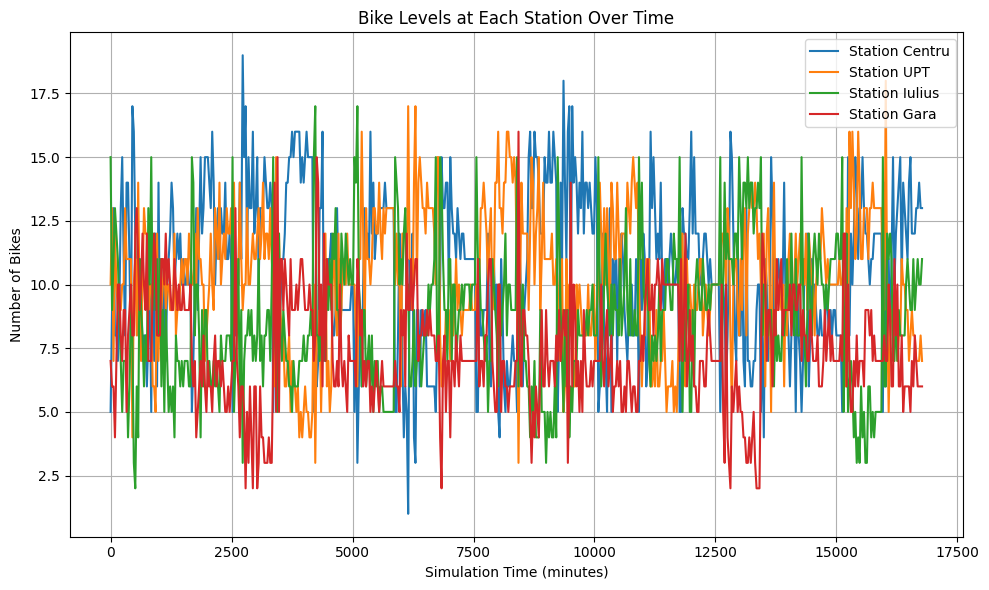

In [483]:
plt.figure(figsize=(10, 6))

for station_name, bikes in station_data.items():
    plt.plot(time_data, bikes, label=f"Station {station_name}")

plt.title("Bike Levels at Each Station Over Time")
plt.xlabel("Simulation Time (minutes)")
plt.ylabel("Number of Bikes")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Total simulation time: 16770 minutes
Number of days: 20


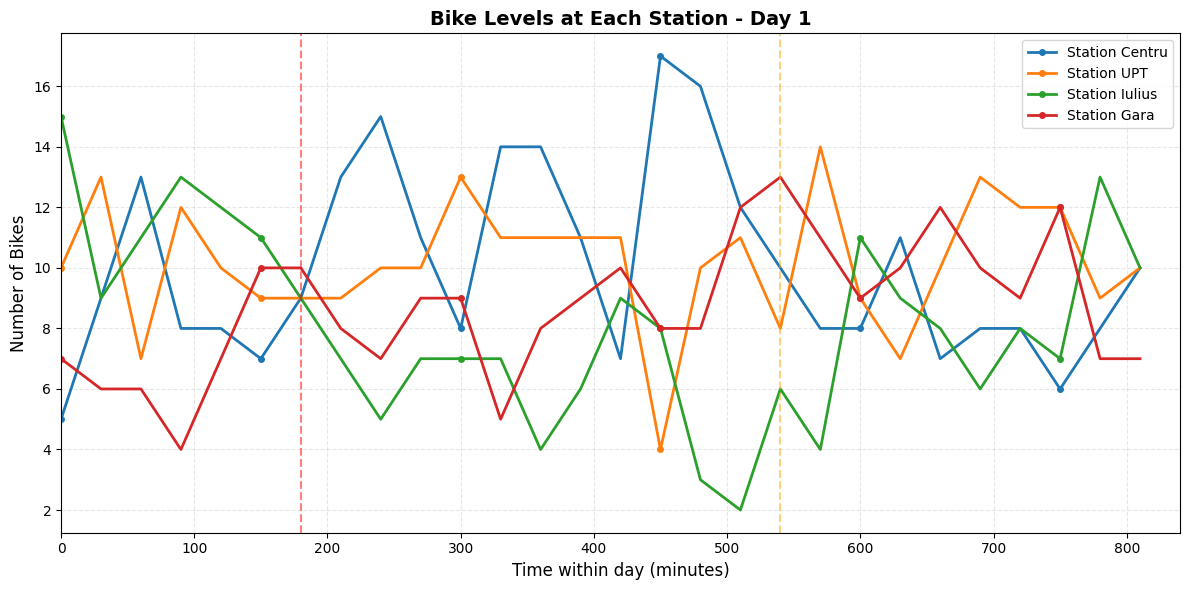


Day 1 Summary:
  Station Centru: Started with 5 bikes, ended with 10 bikes
  Station UPT: Started with 10 bikes, ended with 10 bikes
  Station Iulius: Started with 15 bikes, ended with 10 bikes
  Station Gara: Started with 7 bikes, ended with 7 bikes


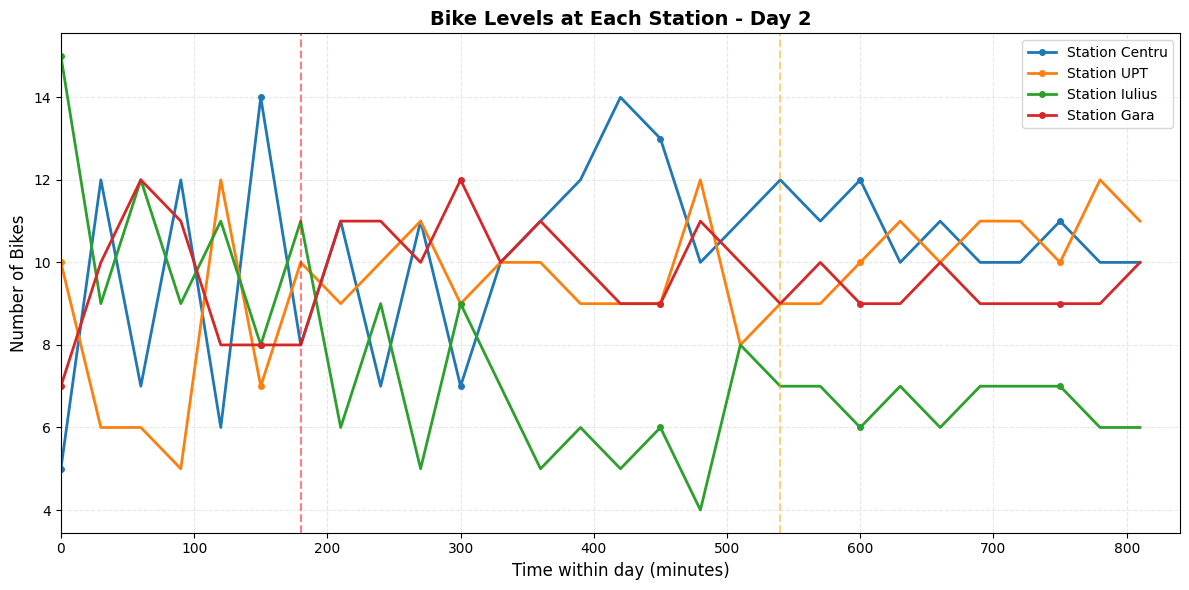


Day 2 Summary:
  Station Centru: Started with 5 bikes, ended with 10 bikes
  Station UPT: Started with 10 bikes, ended with 11 bikes
  Station Iulius: Started with 15 bikes, ended with 6 bikes
  Station Gara: Started with 7 bikes, ended with 10 bikes


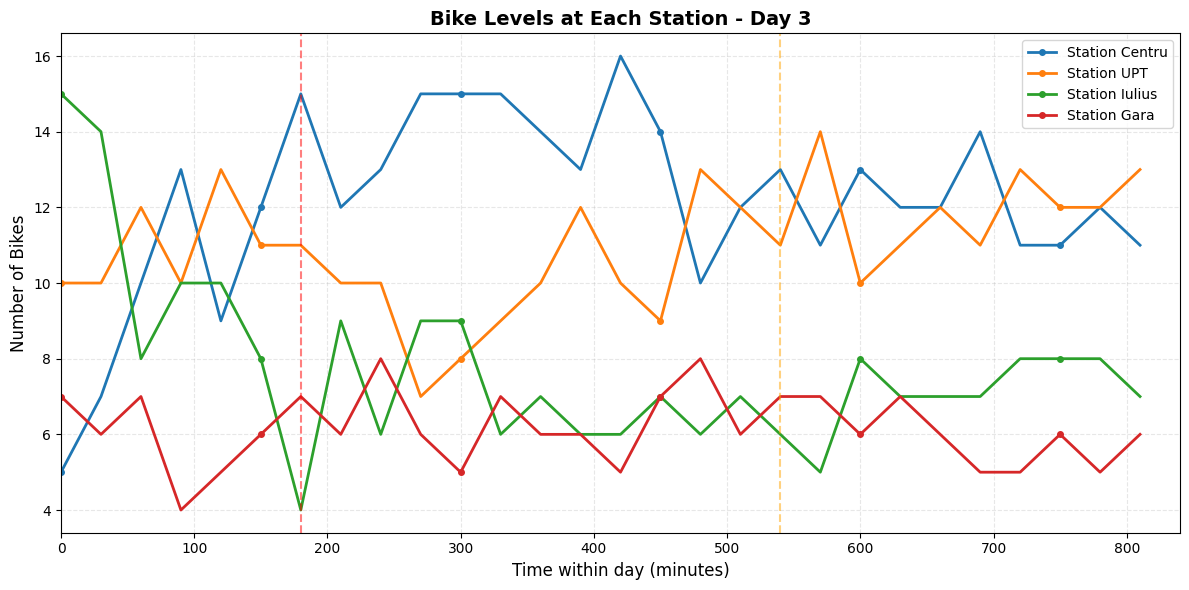


Day 3 Summary:
  Station Centru: Started with 5 bikes, ended with 11 bikes
  Station UPT: Started with 10 bikes, ended with 13 bikes
  Station Iulius: Started with 15 bikes, ended with 7 bikes
  Station Gara: Started with 7 bikes, ended with 6 bikes


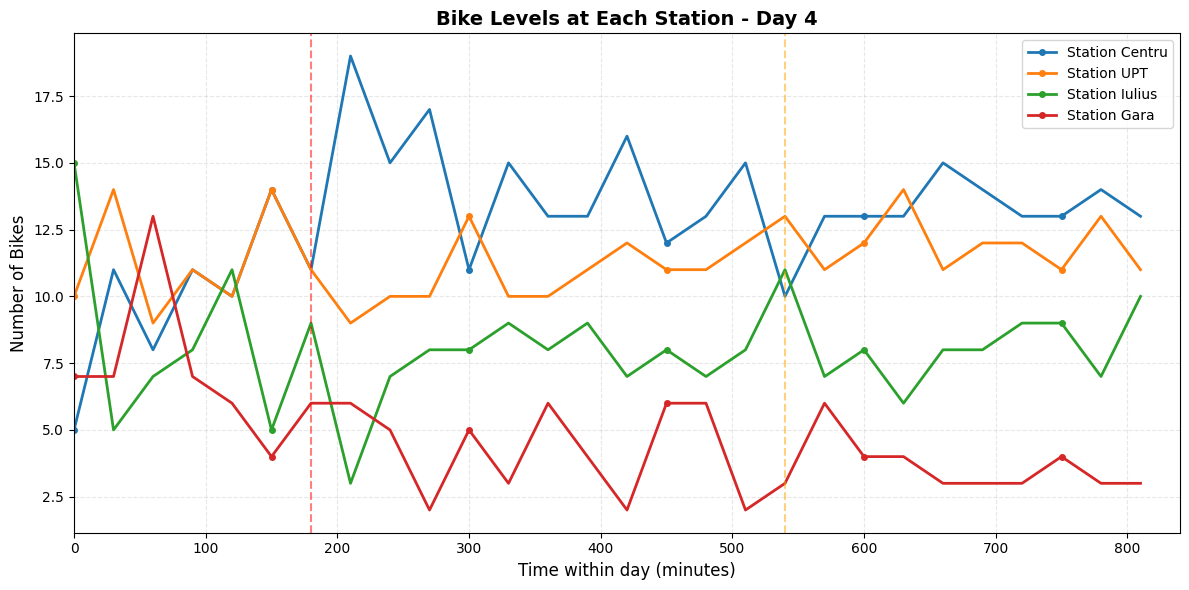


Day 4 Summary:
  Station Centru: Started with 5 bikes, ended with 13 bikes
  Station UPT: Started with 10 bikes, ended with 11 bikes
  Station Iulius: Started with 15 bikes, ended with 10 bikes
  Station Gara: Started with 7 bikes, ended with 3 bikes


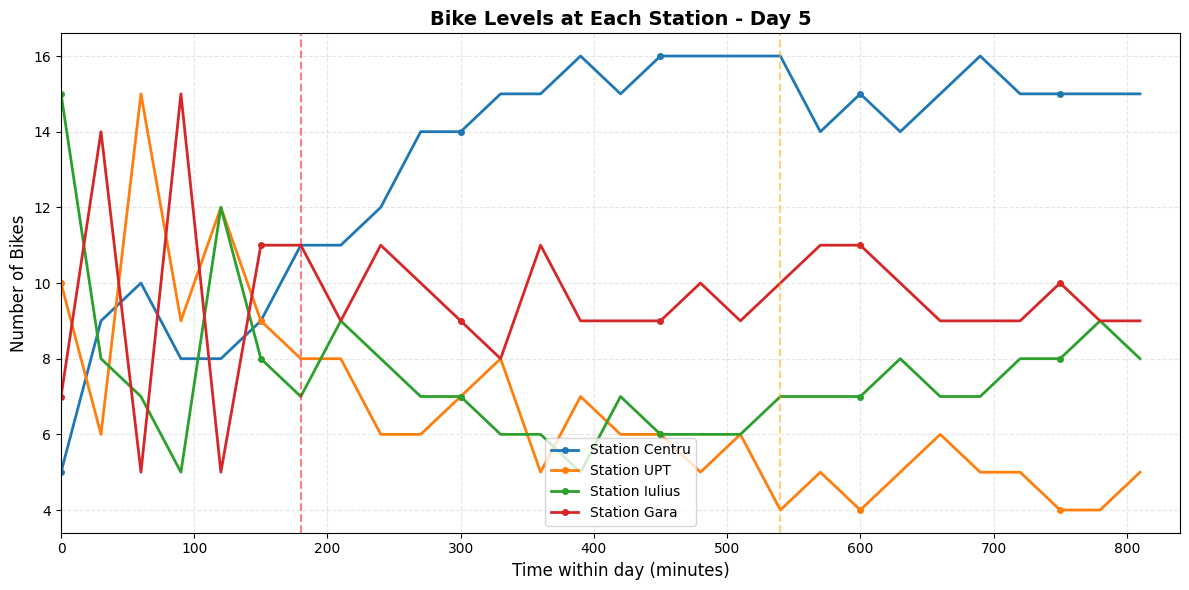


Day 5 Summary:
  Station Centru: Started with 5 bikes, ended with 15 bikes
  Station UPT: Started with 10 bikes, ended with 5 bikes
  Station Iulius: Started with 15 bikes, ended with 8 bikes
  Station Gara: Started with 7 bikes, ended with 9 bikes


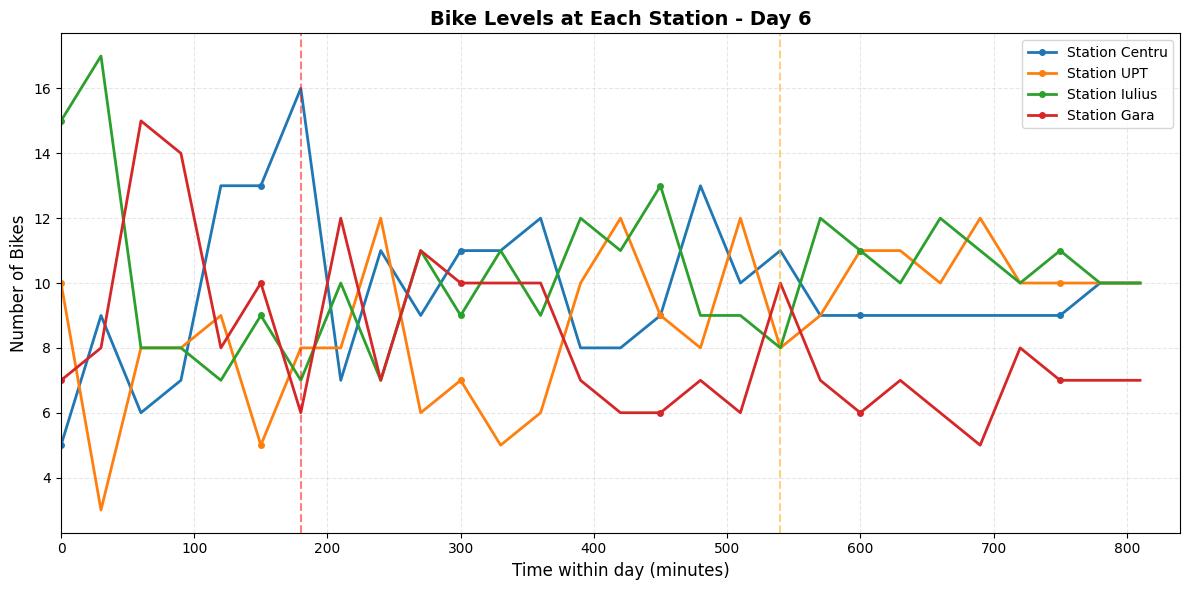


Day 6 Summary:
  Station Centru: Started with 5 bikes, ended with 10 bikes
  Station UPT: Started with 10 bikes, ended with 10 bikes
  Station Iulius: Started with 15 bikes, ended with 10 bikes
  Station Gara: Started with 7 bikes, ended with 7 bikes


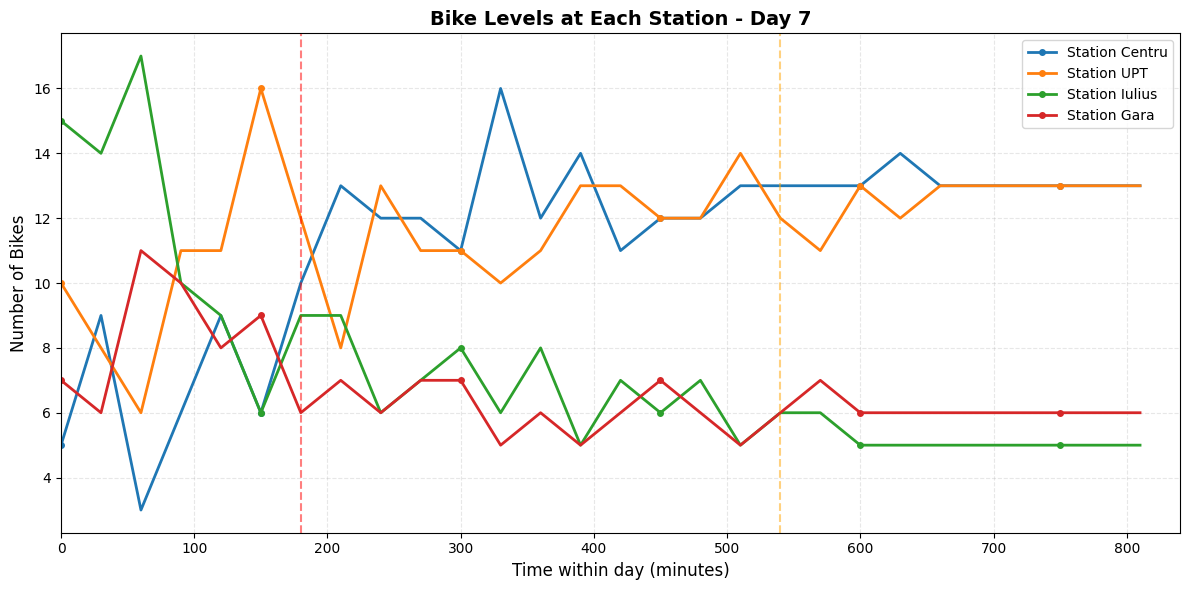


Day 7 Summary:
  Station Centru: Started with 5 bikes, ended with 13 bikes
  Station UPT: Started with 10 bikes, ended with 13 bikes
  Station Iulius: Started with 15 bikes, ended with 5 bikes
  Station Gara: Started with 7 bikes, ended with 6 bikes


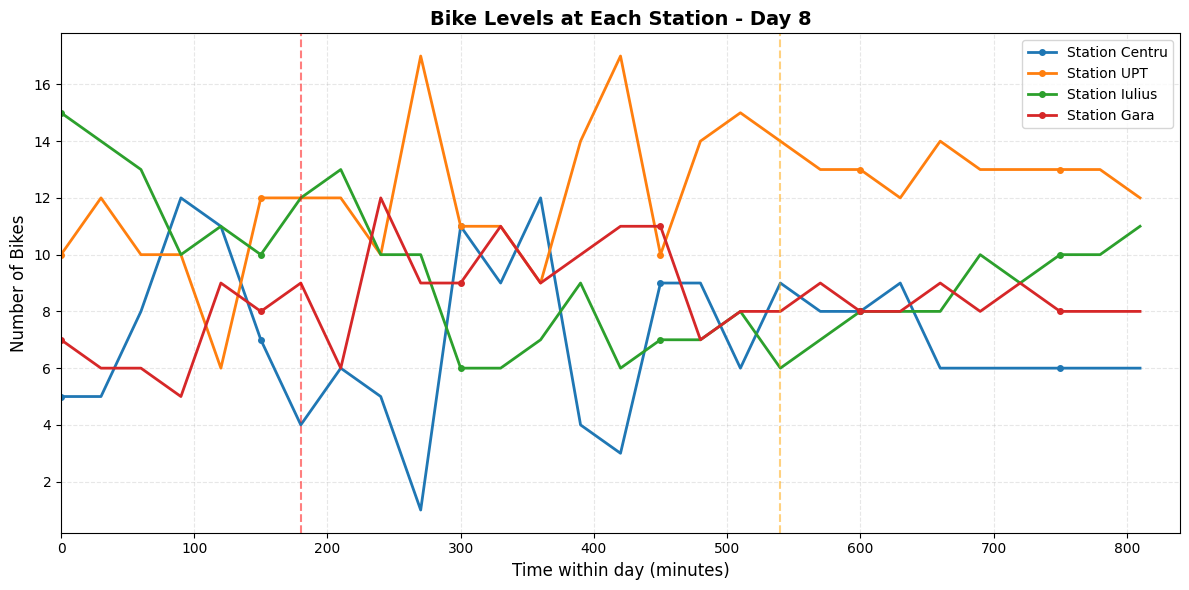


Day 8 Summary:
  Station Centru: Started with 5 bikes, ended with 6 bikes
  Station UPT: Started with 10 bikes, ended with 12 bikes
  Station Iulius: Started with 15 bikes, ended with 11 bikes
  Station Gara: Started with 7 bikes, ended with 8 bikes


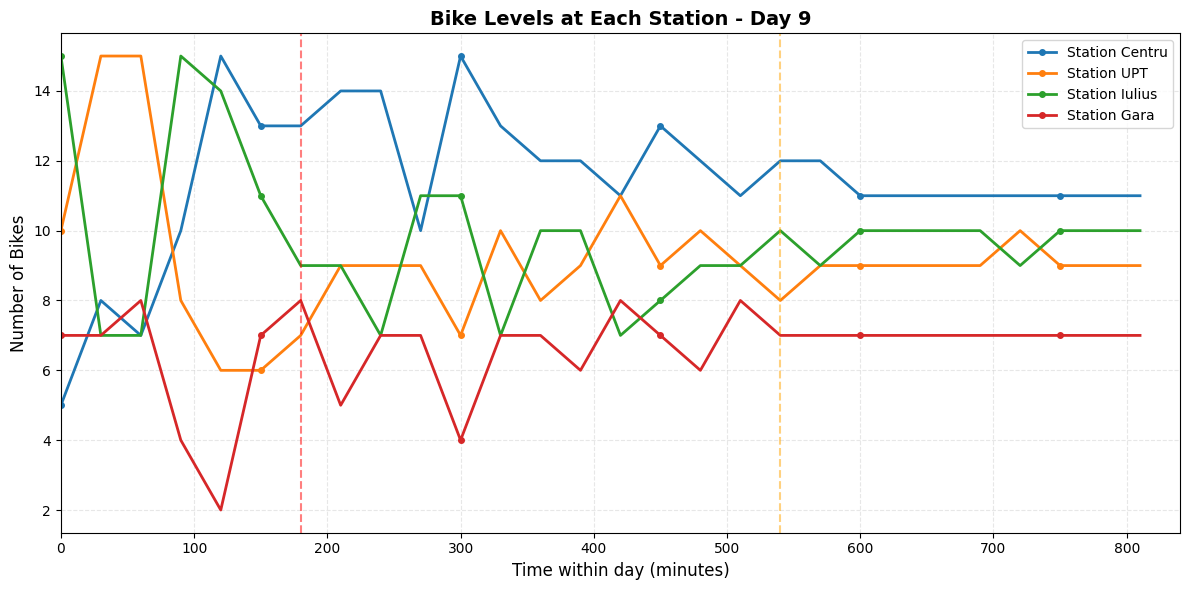


Day 9 Summary:
  Station Centru: Started with 5 bikes, ended with 11 bikes
  Station UPT: Started with 10 bikes, ended with 9 bikes
  Station Iulius: Started with 15 bikes, ended with 10 bikes
  Station Gara: Started with 7 bikes, ended with 7 bikes


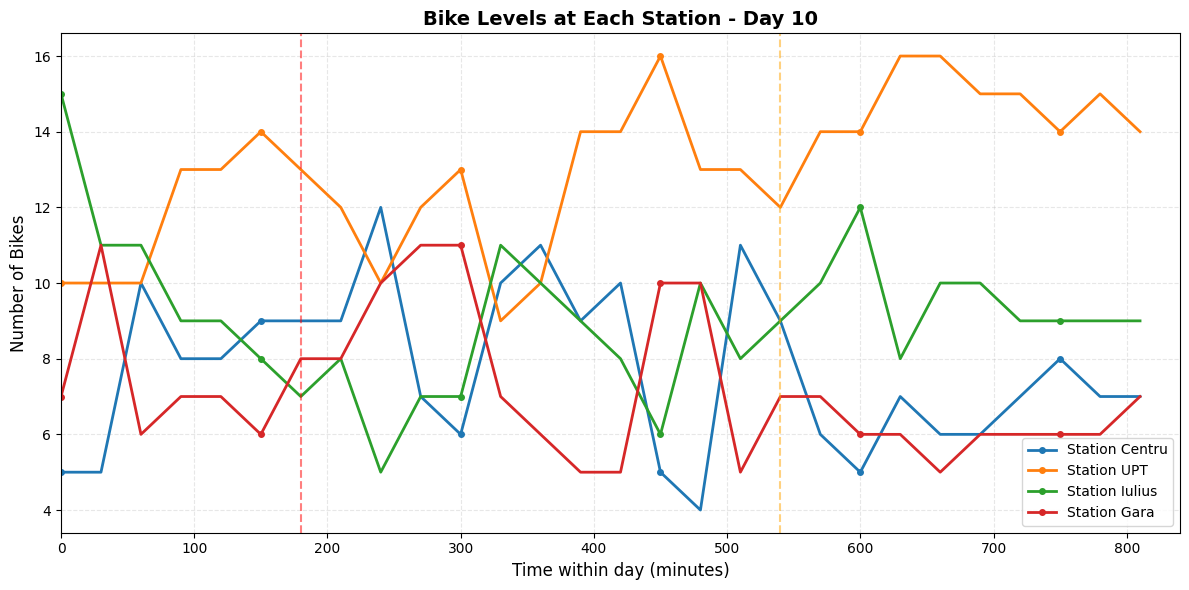


Day 10 Summary:
  Station Centru: Started with 5 bikes, ended with 7 bikes
  Station UPT: Started with 10 bikes, ended with 14 bikes
  Station Iulius: Started with 15 bikes, ended with 9 bikes
  Station Gara: Started with 7 bikes, ended with 7 bikes


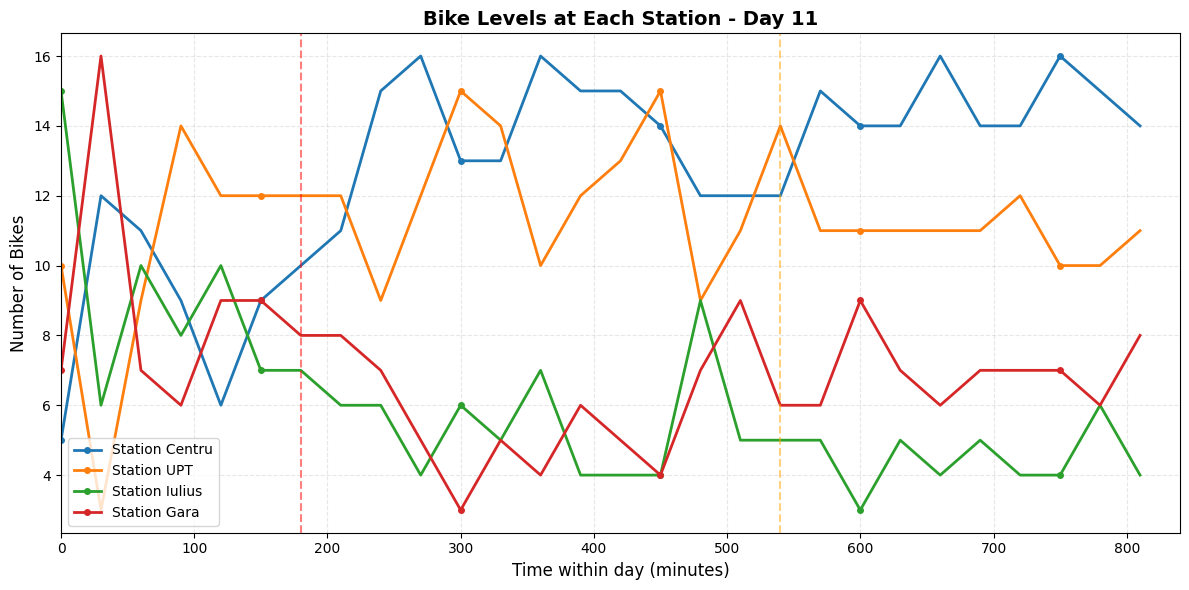


Day 11 Summary:
  Station Centru: Started with 5 bikes, ended with 14 bikes
  Station UPT: Started with 10 bikes, ended with 11 bikes
  Station Iulius: Started with 15 bikes, ended with 4 bikes
  Station Gara: Started with 7 bikes, ended with 8 bikes


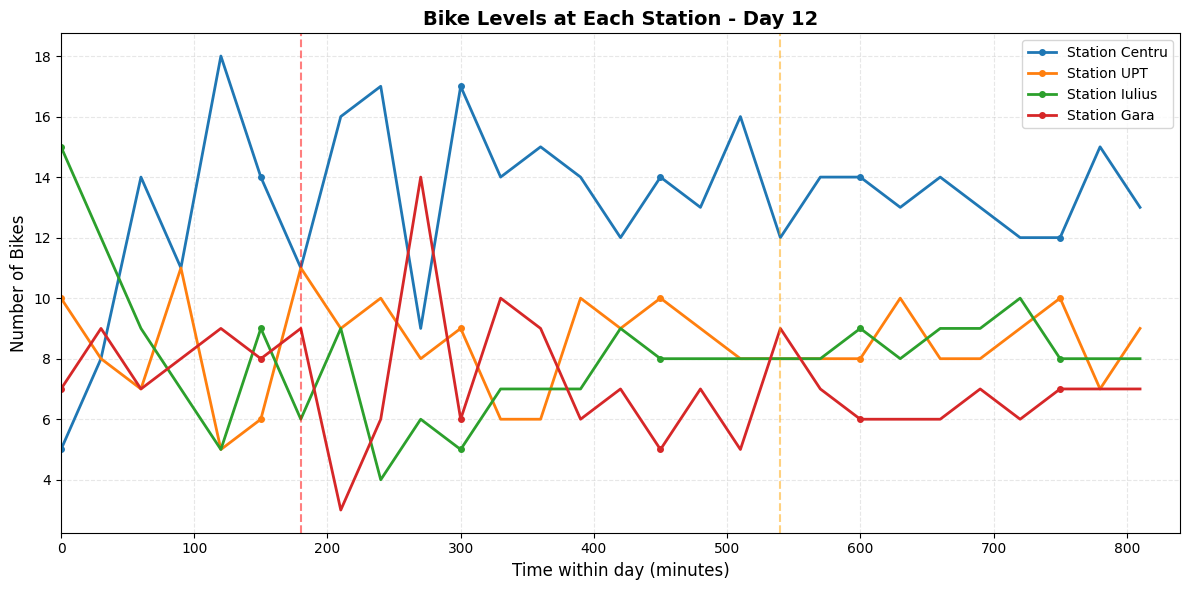


Day 12 Summary:
  Station Centru: Started with 5 bikes, ended with 13 bikes
  Station UPT: Started with 10 bikes, ended with 9 bikes
  Station Iulius: Started with 15 bikes, ended with 8 bikes
  Station Gara: Started with 7 bikes, ended with 7 bikes


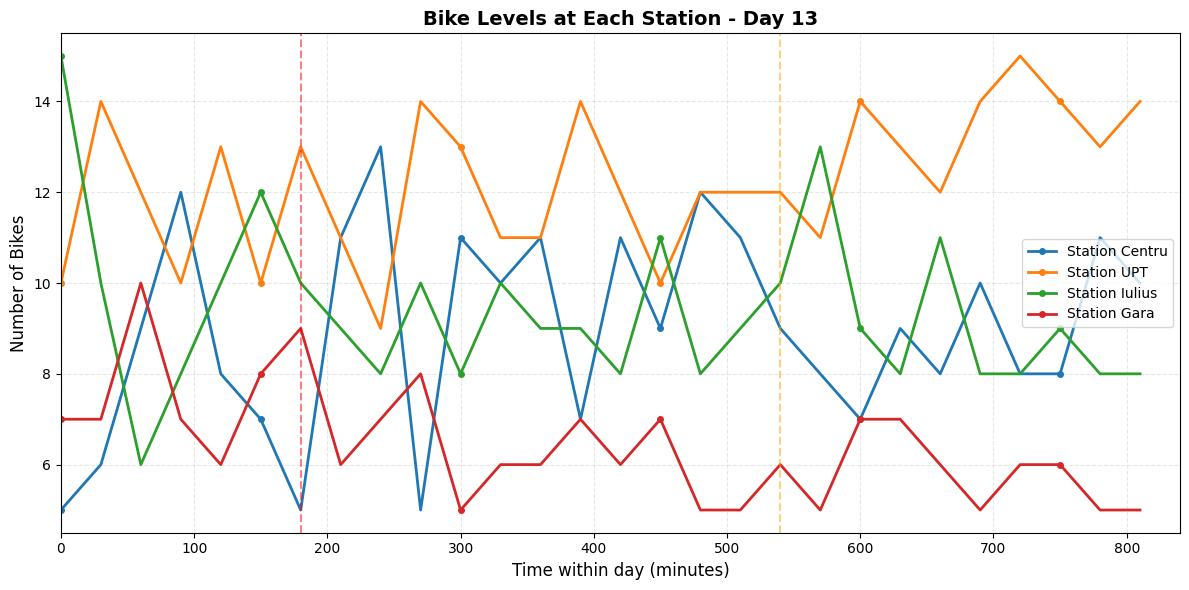


Day 13 Summary:
  Station Centru: Started with 5 bikes, ended with 10 bikes
  Station UPT: Started with 10 bikes, ended with 14 bikes
  Station Iulius: Started with 15 bikes, ended with 8 bikes
  Station Gara: Started with 7 bikes, ended with 5 bikes


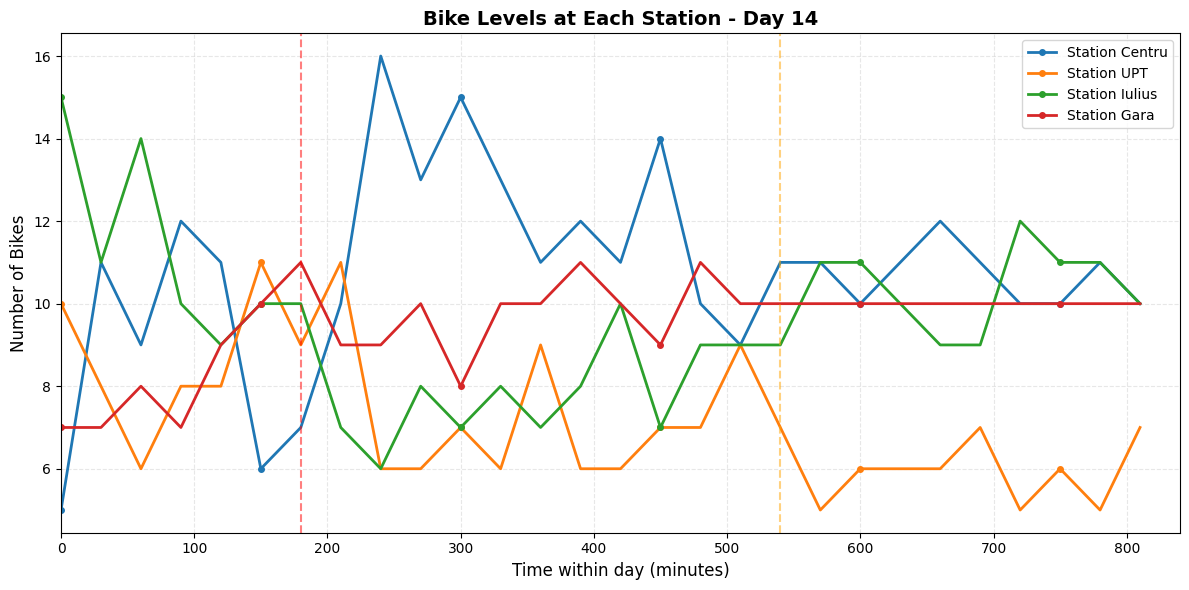


Day 14 Summary:
  Station Centru: Started with 5 bikes, ended with 10 bikes
  Station UPT: Started with 10 bikes, ended with 7 bikes
  Station Iulius: Started with 15 bikes, ended with 10 bikes
  Station Gara: Started with 7 bikes, ended with 10 bikes


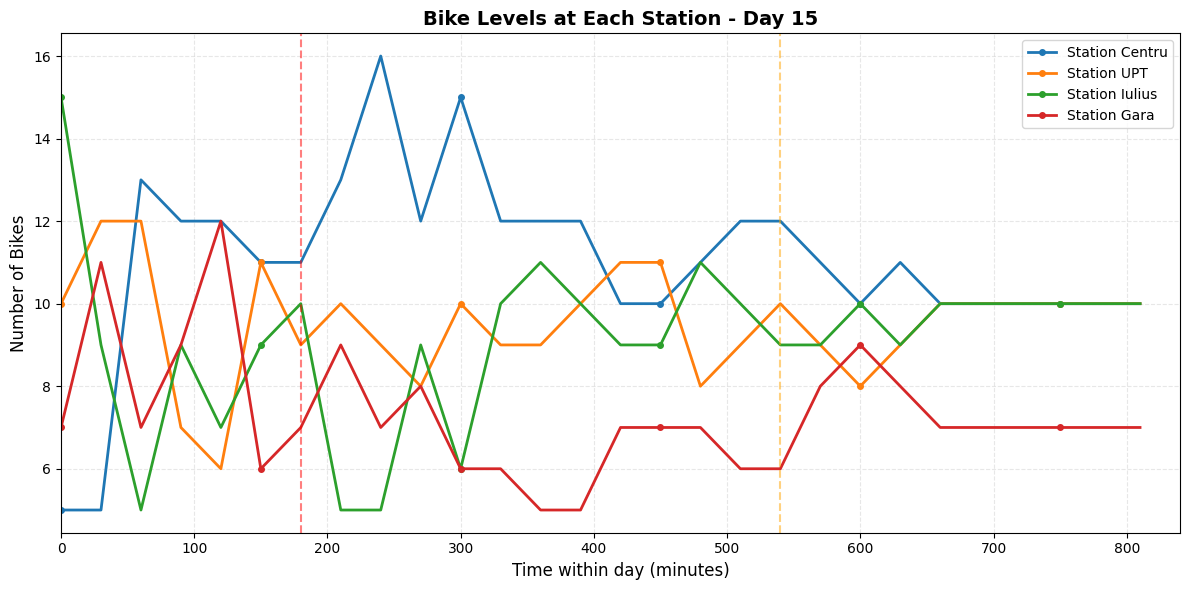


Day 15 Summary:
  Station Centru: Started with 5 bikes, ended with 10 bikes
  Station UPT: Started with 10 bikes, ended with 10 bikes
  Station Iulius: Started with 15 bikes, ended with 10 bikes
  Station Gara: Started with 7 bikes, ended with 7 bikes


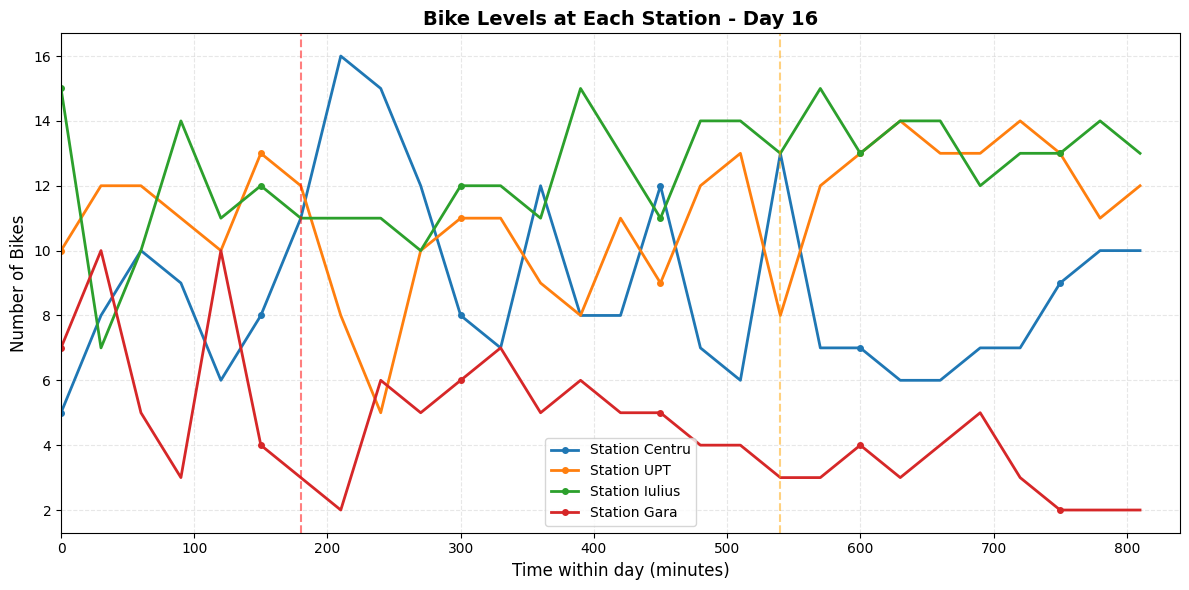


Day 16 Summary:
  Station Centru: Started with 5 bikes, ended with 10 bikes
  Station UPT: Started with 10 bikes, ended with 12 bikes
  Station Iulius: Started with 15 bikes, ended with 13 bikes
  Station Gara: Started with 7 bikes, ended with 2 bikes


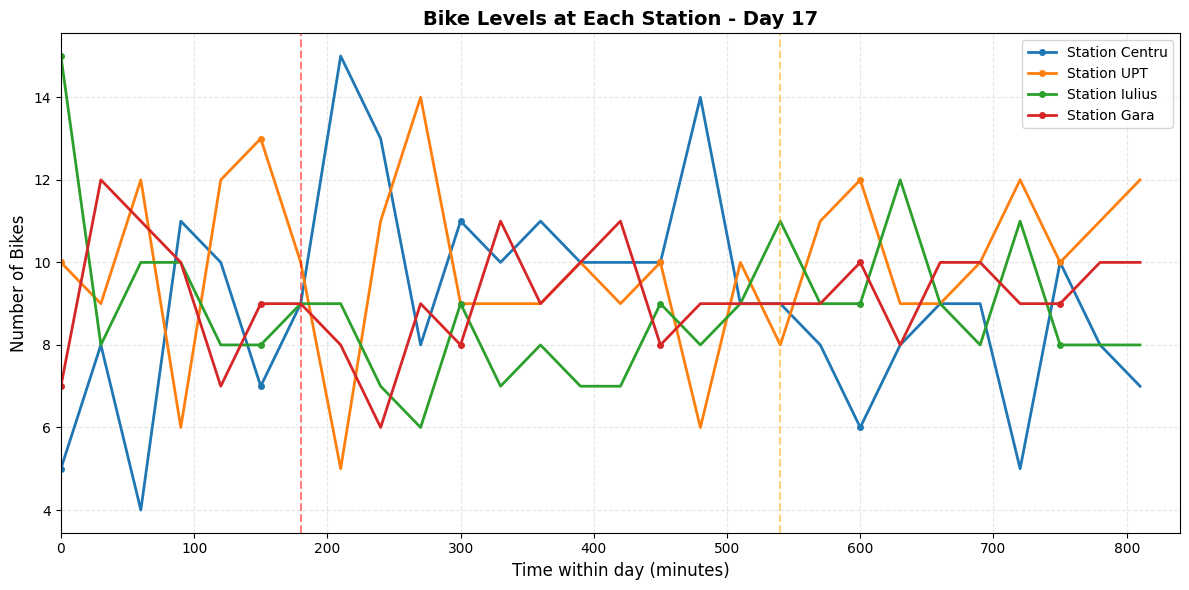


Day 17 Summary:
  Station Centru: Started with 5 bikes, ended with 7 bikes
  Station UPT: Started with 10 bikes, ended with 12 bikes
  Station Iulius: Started with 15 bikes, ended with 8 bikes
  Station Gara: Started with 7 bikes, ended with 10 bikes


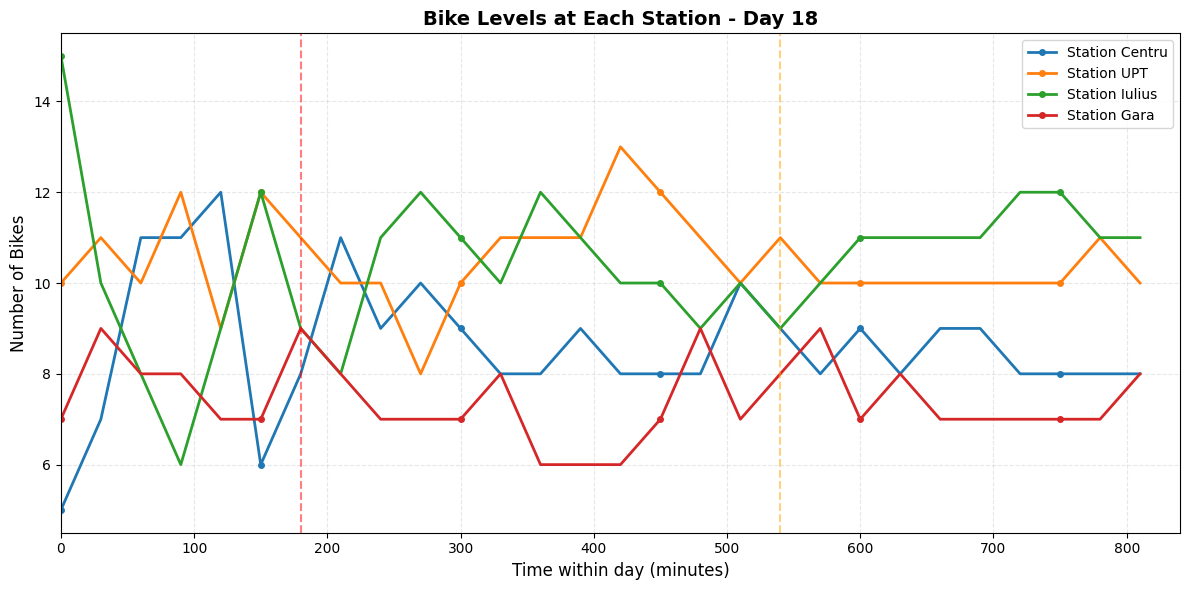


Day 18 Summary:
  Station Centru: Started with 5 bikes, ended with 8 bikes
  Station UPT: Started with 10 bikes, ended with 10 bikes
  Station Iulius: Started with 15 bikes, ended with 11 bikes
  Station Gara: Started with 7 bikes, ended with 8 bikes


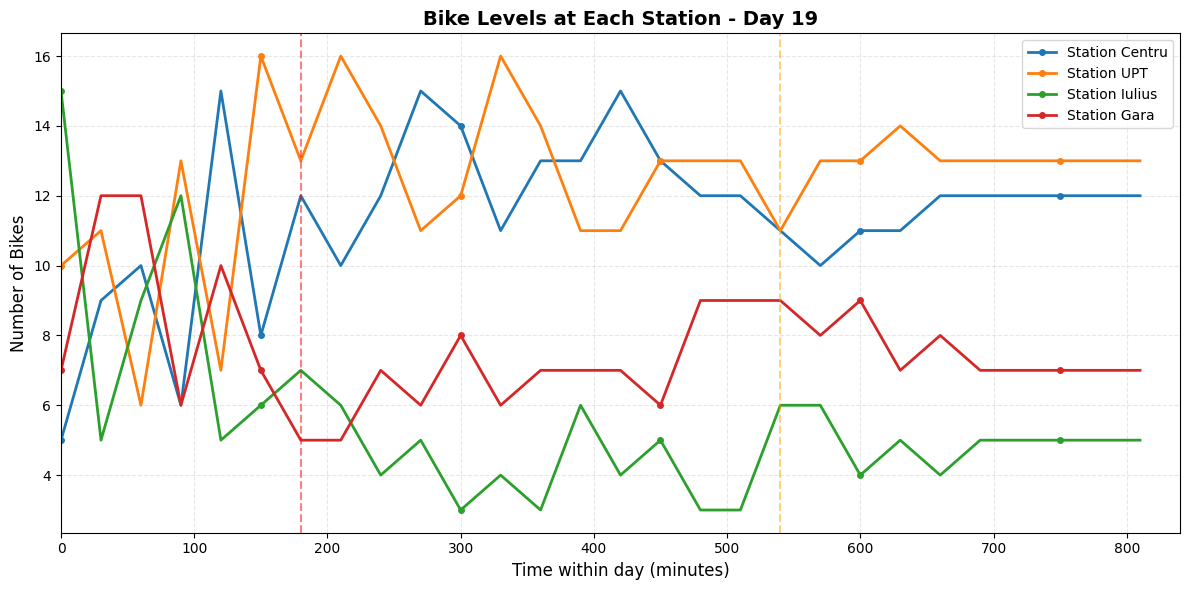


Day 19 Summary:
  Station Centru: Started with 5 bikes, ended with 12 bikes
  Station UPT: Started with 10 bikes, ended with 13 bikes
  Station Iulius: Started with 15 bikes, ended with 5 bikes
  Station Gara: Started with 7 bikes, ended with 7 bikes


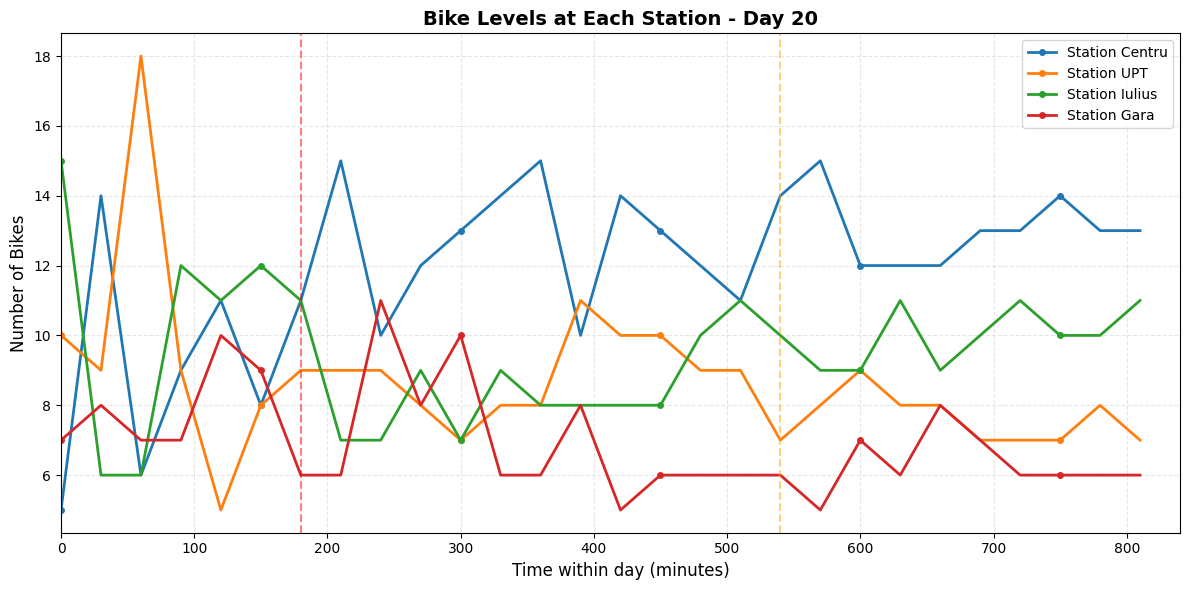


Day 20 Summary:
  Station Centru: Started with 5 bikes, ended with 13 bikes
  Station UPT: Started with 10 bikes, ended with 7 bikes
  Station Iulius: Started with 15 bikes, ended with 11 bikes
  Station Gara: Started with 7 bikes, ended with 6 bikes


In [484]:
import numpy as np

# Determine how many complete days we have
total_time = time_data[-1] if time_data else 0
num_days = int(total_time / 840) + 1

print(f"Total simulation time: {total_time} minutes")
print(f"Number of days: {num_days}")

# Create a plot for each day
for day in range(num_days):
    day_start = day * 840
    day_end = (day + 1) * 840

    day_indices = [i for i, t in enumerate(time_data) if day_start <= t < day_end]

    if not day_indices:
        continue

    # Extract time and data for this day
    day_time_data = [time_data[i] - day_start for i in day_indices]  # Normalize to start at 0
    day_station_data = {station: [station_data[station][i] for i in day_indices]
                        for station in station_data.keys()}

    # Create the plot
    plt.figure(figsize=(12, 6))

    for station_name, bikes in day_station_data.items():
        plt.plot(day_time_data, bikes, label=f"Station {station_name}", linewidth=2, marker='o', markersize=4, markevery=5)

    plt.title(f"Bike Levels at Each Station - Day {day + 1}", fontsize=14, fontweight='bold')
    plt.xlabel("Time within day (minutes)", fontsize=12)
    plt.ylabel("Number of Bikes", fontsize=12)
    plt.legend(fontsize=10)
    plt.grid(True, alpha=0.3, linestyle='--')
    plt.xlim(0, 840)

    # Add vertical lines for time slots
    plt.axvline(x=180, color='red', linestyle='--', alpha=0.5, label='Morning End')
    plt.axvline(x=540, color='orange', linestyle='--', alpha=0.5, label='Midday End')

    plt.tight_layout()
    plt.show()

    # Print summary for this day
    print(f"\nDay {day + 1} Summary:")
    for station_name in day_station_data.keys():
        start_bikes = day_station_data[station_name][0] if day_station_data[station_name] else 0
        end_bikes = day_station_data[station_name][-1] if day_station_data[station_name] else 0
        print(f"  Station {station_name}: Started with {start_bikes} bikes, ended with {end_bikes} bikes")

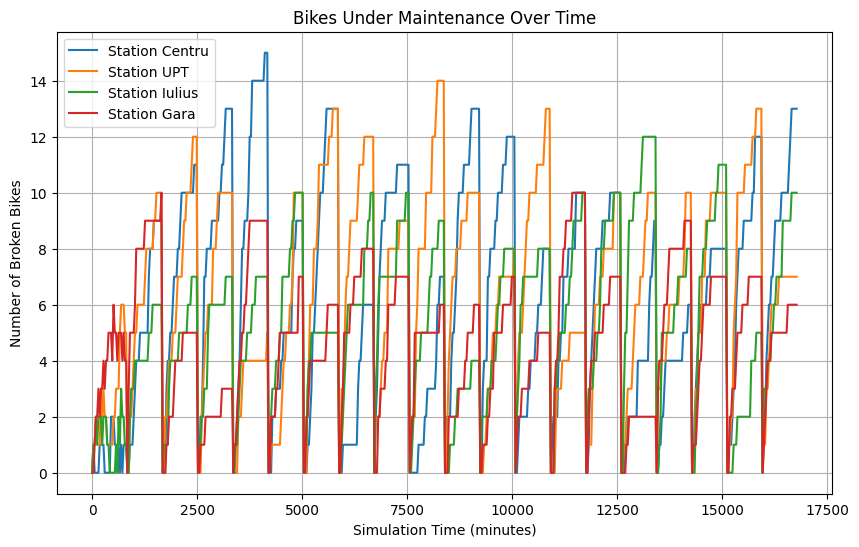

In [485]:
plt.figure(figsize=(10, 6))
for station_name, broken in broken_bikes_data.items():
    plt.plot(time_data, broken, label=f"Station {station_name}")
plt.title("Bikes Under Maintenance Over Time")
plt.xlabel("Simulation Time (minutes)")
plt.ylabel("Number of Broken Bikes")
plt.legend()
plt.grid(True)
plt.show()

<Figure size 1400x700 with 0 Axes>

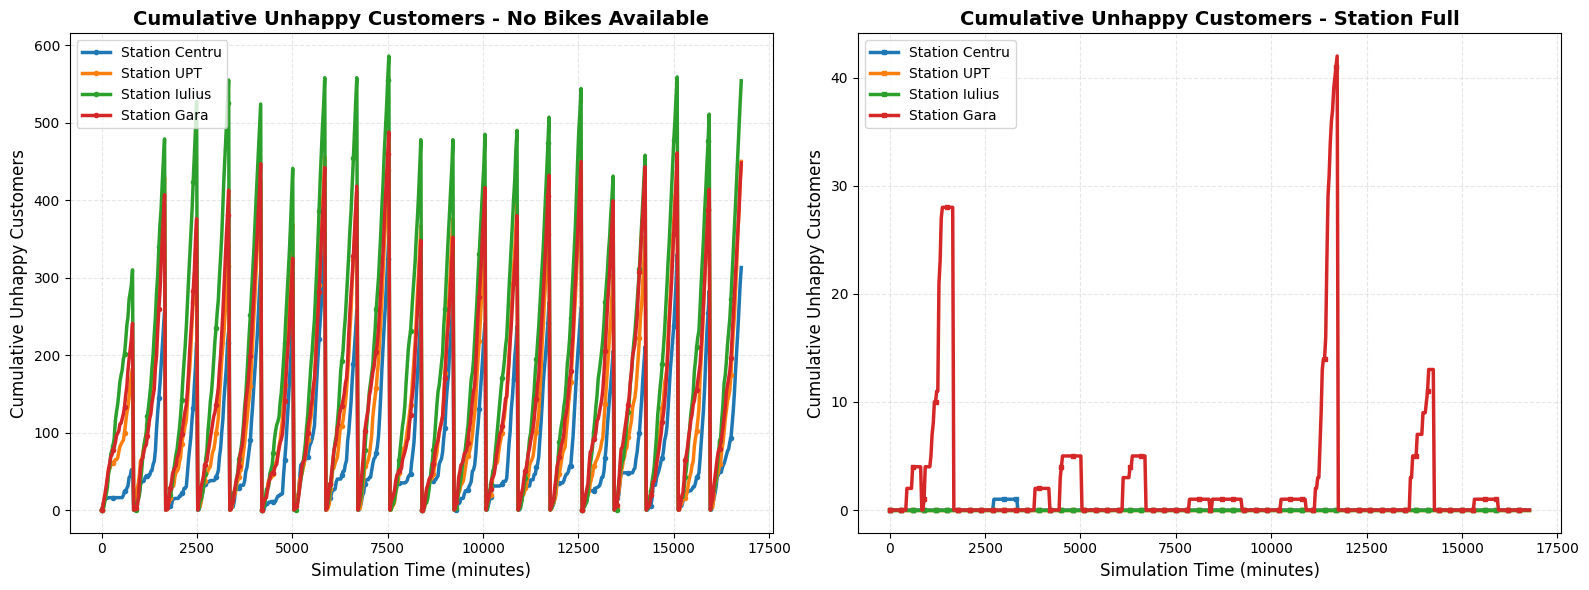

In [486]:
plt.figure(figsize=(14, 7))

# Create subplots - 2 graphs side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Left plot: No Bikes Available
for station_name, unhappy_data in unhappy_no_bikes_data.items():
    ax1.plot(time_data, unhappy_data, label=f"Station {station_name}", linewidth=2.5, marker='o', markersize=3, markevery=10)

ax1.set_title("Cumulative Unhappy Customers - No Bikes Available", fontsize=14, fontweight='bold')
ax1.set_xlabel("Simulation Time (minutes)", fontsize=12)
ax1.set_ylabel("Cumulative Unhappy Customers", fontsize=12)
ax1.legend(fontsize=10, loc='upper left')
ax1.grid(True, alpha=0.3, linestyle='--')

# Right plot: Station Full
for station_name, unhappy_data in unhappy_station_full_data.items():
    ax2.plot(time_data, unhappy_data, label=f"Station {station_name}", linewidth=2.5, marker='s', markersize=3, markevery=10)

ax2.set_title("Cumulative Unhappy Customers - Station Full", fontsize=14, fontweight='bold')
ax2.set_xlabel("Simulation Time (minutes)", fontsize=12)
ax2.set_ylabel("Cumulative Unhappy Customers", fontsize=12)
ax2.legend(fontsize=10, loc='upper left')
ax2.grid(True, alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()
